# 03. Can the models be trusted?

Three checks, with pass marks fixed in the analysis specification. A model goes forward only if it passes all three.

1. **Fitting worked.** Did the estimation settle?
2. **Basic-trial match.** Do simulated copies behave like the real people on the trials they learned from?
3. **Parameter recovery.** If we invent people with traits we chose ourselves, does the model get those traits back?

Run notebook 02 first.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")
import dd

# QUICK = True runs a 5-minute version on 8 people to check that everything works.
# QUICK = False is the real analysis (rung 2 takes the longest; see notebook 02a for a time estimate).
QUICK = False
N_PEOPLE = 8 if QUICK else None
CHAINS, WARMUP, SAMPLES = (2, 150, 150) if QUICK else (4, 500, 500)
TAG = "quick" if QUICK else "basic"
RUNGS = ["rung0", "rung1", "rung2"]
N_REPS = 20 if QUICK else 200       # how many times each copy repeats the task
import matplotlib.pyplot as plt
COL = {"real": "#0b0b0b", "rung0": "#8a8984", "rung1": "#eb6834", "rung2": "#2a78d6"}
NAME = {"rung0": "Rung 0 · simple statistics", "rung1": "Rung 1 · patience", "rung2": "Rung 2 · patience + decision time"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2})
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); plt.show()

In [2]:
d = dd.reindex(dd.load_trials(), N_PEOPLE)
basic = d[d.condition == "basic"].reset_index(drop=True)
amt, delay, u = basic.later_amount.values, basic.delay.values, basic.u.values
min_rt = basic.groupby("u").rt.min().sort_index().values

## Check 1: Fitting worked
Pass mark: max R-hat below 1.01, no divergent transitions, at least 400 effective samples.

In [3]:
diag = pd.read_csv(dd.FIT_DIR / f"diagnostics_{TAG}.csv", index_col=0)
diag

,max_rhat,min_ess,divergent,max_treedepth_share,minutes,passed
rung,,,,,,
rung0,1.005,481,0,0.0,1.0,True
rung1,1.004,1535,0,0.0,1.2,True
rung2,1.005,541,0,0.0,50.9,True


## Check 2: Basic-trial match
Each simulated copy redoes its person's basic trials many times. Each repeat uses a different plausible version of that person's traits, so the spread reflects what the model is unsure about.

The grey band is where the simulated copies fall 95% of the time. The black dots are the real people. Dots inside the band = pass.

Rungs 0 and 1 have no model of time, so only rung 2 is checked on response times.

In [4]:
rng = np.random.default_rng(1)
def simulate_copies(rung, n_reps):
    th_all = dd.load_draws(rung, TAG)["theta"]
    pick = rng.choice(th_all.shape[0], size=n_reps, replace=False)
    sims = []
    for i in pick:
        th = th_all[i][u - 1]                                   # each trial gets its person-session's traits
        ch, rt = dd.simulate(rung, th, amt, delay, rng, min_rt=min_rt[u - 1], rt_pool=None)
        sims.append((ch, rt))
    return sims

sims = {}
for rung in RUNGS:
    t0 = time.time(); sims[rung] = simulate_copies(rung, N_REPS); print(rung, f"simulated in {time.time() - t0:.0f} s")

rung0 simulated in 0 s
rung1 simulated in 0 s
rung2 simulated in 46 s


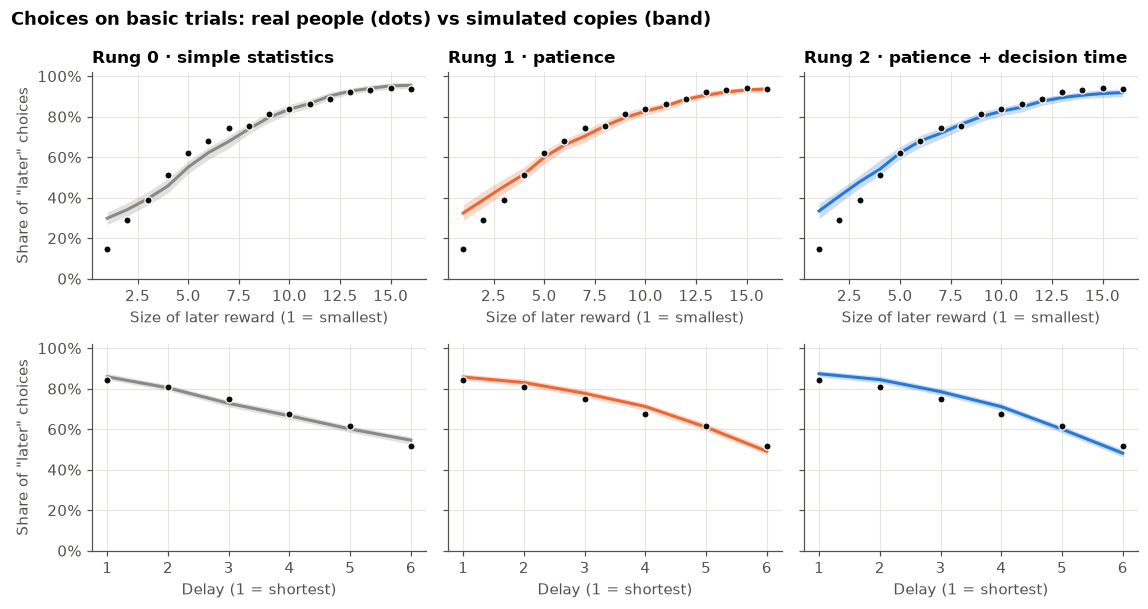

,reward sizes inside band,delays inside band
rung0,9 of 16,3 of 6
rung1,12 of 16,1 of 6
rung2,9 of 16,1 of 6


In [5]:
def band(values):   # values: reps x levels
    return np.quantile(values, [0.025, 0.5, 0.975], axis=0)

inside = {}
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6), sharey=True)
for j, rung in enumerate(RUNGS):
    for i, (lev, xl) in enumerate([("amount_level", "Size of later reward (1 = smallest)"), ("delay_level", "Delay (1 = shortest)")]):
        ax = axes[i, j]; levels = np.sort(basic[lev].unique())
        real = basic.groupby(lev).choice.mean().reindex(levels).values
        sim = np.array([pd.Series(ch).groupby(basic[lev].values).mean().reindex(levels).values for ch, _ in sims[rung]])
        lo, mid, hi = band(sim)
        ax.fill_between(levels, lo, hi, color=COL[rung], alpha=0.25, lw=0); ax.plot(levels, mid, color=COL[rung])
        ax.scatter(levels, real, s=22, color=COL["real"], zorder=3, edgecolor="white", linewidth=0.8)
        inside[(rung, lev)] = f"{int(((real >= lo) & (real <= hi)).sum())} of {len(levels)}"
        ax.set_xlabel(xl); ax.set_ylim(0, 1.02)
        if i == 0: ax.set_title(NAME[rung])
        if j == 0: ax.set_ylabel('Share of "later" choices'); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.suptitle("Choices on basic trials: real people (dots) vs simulated copies (band)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_basic_match_choices")
pd.Series(inside).unstack().rename(columns={"amount_level": "reward sizes inside band", "delay_level": "delays inside band"})

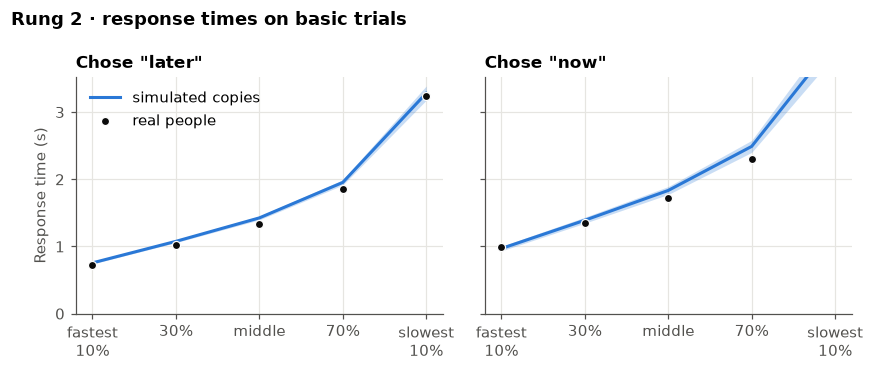

{'Chose "later"': '1 of 5', 'Chose "now"': '1 of 5'}

In [ ]:
qs = [0.1, 0.3, 0.5, 0.7, 0.9]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), sharey=True)
rt_inside = {}
for ax, (c, lab) in zip(axes, [(1, 'Chose "later"'), (0, 'Chose "now"')]):
    real = np.quantile(basic.rt[basic.choice == c], qs)
    sim = np.array([np.quantile(rt[ch == c], qs) for ch, rt in sims["rung2"]])
    lo, mid, hi = band(sim)
    ax.fill_between(range(5), lo, hi, color=COL["rung2"], alpha=0.25, lw=0); ax.plot(range(5), mid, color=COL["rung2"], label="simulated copies")
    ax.scatter(range(5), real, s=28, color=COL["real"], zorder=3, edgecolor="white", linewidth=0.8, label="real people")
    rt_inside[lab] = f"{int(((real >= lo) & (real <= hi)).sum())} of 5"
    ax.set_xticks(range(5)); ax.set_xticklabels(["fastest\n10%", "30%", "middle", "70%", "slowest\n10%"]); ax.set_title(lab); axes[0].set_ylim(0, max(a.get_ylim()[1] for a in axes))
axes[0].set_ylabel("Response time (s)"); axes[0].legend(loc="upper left")
fig.suptitle("Rung 2 · response times on basic trials", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_basic_match_rt")
rt_inside

## Check 3: Parameter recovery
Like testing a kitchen scale with a weight you already know.

1. Invent fake people. Their traits are drawn from the group pattern found in notebook 02, so they are realistic, but **we** choose the numbers.
2. Each fake person does the real basic-trial lists inside the computer.
3. Fit the model to this fake data without telling it the traits.
4. Compare what the model says with what we chose.

Pass mark: correlation above 0.8 between chosen and estimated values, for each trait. Done for rungs 1 and 2, the rungs whose traits are used later.

In [7]:
def invent_people(rung, rng):
    dr = dd.load_draws(rung, TAG)
    mu, sp, ss = dr["mu"].mean(0), dr["sigma_p"].mean(0), dr["sigma_s"].mean(0)
    P, U = basic.p.max(), basic.u.max()
    person_of_unit = basic.groupby("u").p.first().sort_index().values
    theta_p = mu + sp * rng.standard_normal((P, len(mu)))
    return theta_p[person_of_unit - 1] + ss * rng.standard_normal((U, len(mu)))     # true traits, units x traits

recovery, truth, est = [], {}, {}
rng = np.random.default_rng(2)
for rung in ["rung1", "rung2"]:
    true = invent_people(rung, rng)
    ch, rt = dd.simulate(rung, true[u - 1], amt, delay, rng, min_rt=min_rt[u - 1])
    fake = basic.assign(choice=ch, rt=rt if rung == "rung2" else basic.rt)
    f = dd.fit(rung, dd.stan_data(fake, with_rt=(rung == "rung2")), chains=CHAINS, warmup=WARMUP, samples=SAMPLES, seed=3)
    got = f.stan_variable("theta").mean(0)
    if rung == "rung2":   # non-decision time is defined relative to each unit's fastest response; compare in seconds
        true = true.copy(); got = got.copy()
        true[:, 2] = min_rt / (1 + np.exp(-true[:, 2]))
        got[:, 2] = fake.groupby("u").rt.min().sort_index().values / (1 + np.exp(-got[:, 2]))
    truth[rung], est[rung] = true, got
    for kk, trait in enumerate(dd.TRAITS[rung]):
        recovery.append({"rung": rung, "trait": trait, "correlation": np.corrcoef(true[:, kk], got[:, kk])[0, 1], **dd.diagnostics(f)})
rec = pd.DataFrame(recovery); rec["passed"] = rec.correlation > 0.8
rec.to_csv(dd.FIT_DIR / f"recovery_{TAG}.csv", index=False)
rec.round(3)

19:38:07 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/1000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/1000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/1000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/1000 [00:00<?, ?it/s, (Warmup)]

19:39:12 - cmdstanpy - INFO - CmdStan done processing.
19:39:12 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in 'rung1_hyperbolic.stan', line 30, column 17 to column 58)
Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in 'rung1_hyperbolic.stan', line 30, column 17 to column 58)
Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in 'rung1_hyperbolic.stan', line 30, column 17 to column 58)
Consider re-running with show_console=True if the above output is unclear!


... (3 outputs left out)

chain 3:   0%|          | 0/1000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/1000 [00:00<?, ?it/s, (Warmup)]

20:59:20 - cmdstanpy - INFO - CmdStan done processing.
20:59:20 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: wiener_lpdf: Boundary separation[1] is inf, but must be positive finite! (in 'rung2_ddm.stan', line 63, column 2 to column 73)
	Exception: wiener_lpdf: Boundary separation[1] is inf, but must be positive finite! (in 'rung2_ddm.stan', line 63, column 2 to column 73)
	Exception: wiener_lpdf: Boundary separation[1] is inf, but must be positive finite! (in 'rung2_ddm.stan', line 63, column 2 to column 73)
	Exception: wiener_lpdf: Boundary separation[1] is inf, but must be positive finite! (in 'rung2_ddm.stan', line 63, column 2 to column 73)
	Exception: wiener_lpdf: Boundary separation[1] is inf, but must be positive finite! (in 'rung2_ddm.stan', line 63, column 2 to column 73)
	Exception: wiener_lpdf: Boundary separation[1] is inf, but must be positive finite! (in 'rung2_ddm.stan', line 63, column 2 to column 73)
Exception: wiener_lpdf: Boundary separation[1]

,rung,trait,correlation,max_rhat,min_ess,divergent,max_treedepth_share,passed
0,rung1,logk,0.968,1.012,886,0,0.0,True
1,rung1,log_beta,0.957,1.012,886,0,0.0,True
2,rung2,logk,0.972,1.014,209,0,0.0,True
3,rung2,log_alpha,0.933,1.014,209,0,0.0,True
4,rung2,logit_tau,0.974,1.014,209,0,0.0,True
5,rung2,logit_bias,0.826,1.014,209,0,0.0,True
6,rung2,log_vmax,0.914,1.014,209,0,0.0,True
7,rung2,log_vcoef,0.841,1.014,209,0,0.0,True


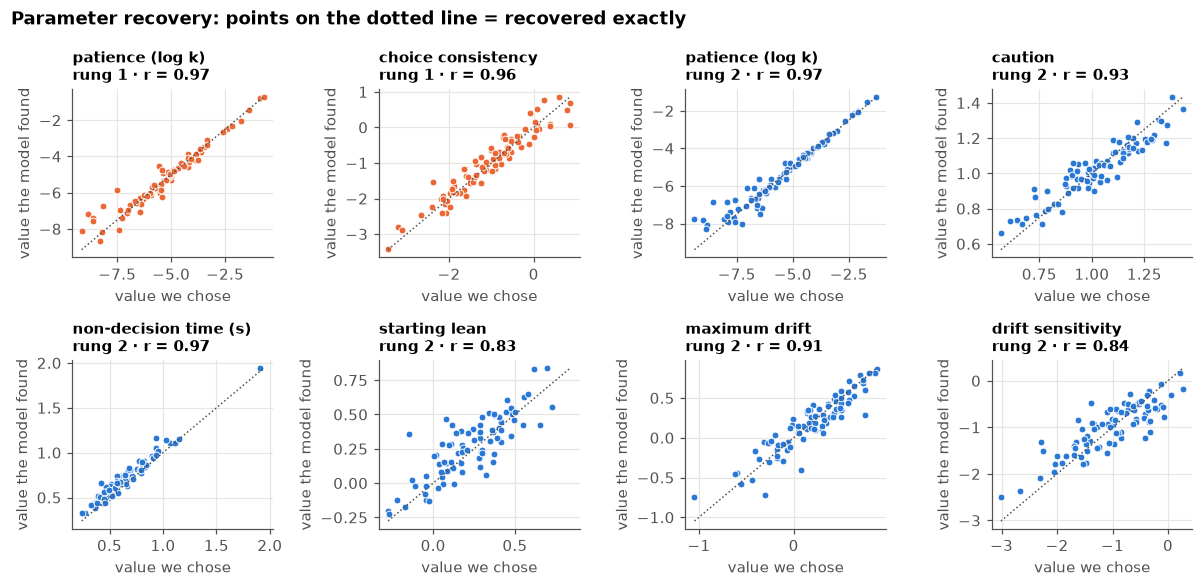

In [8]:
PLAIN = {"logk": "patience (log k)", "log_beta": "choice consistency", "log_alpha": "caution", "logit_tau": "non-decision time (s)",
         "logit_bias": "starting lean", "log_vmax": "maximum drift", "log_vcoef": "drift sensitivity"}
panels = [(r, kk, t) for r in ["rung1", "rung2"] for kk, t in enumerate(dd.TRAITS[r])]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.4)); axes = axes.ravel()
for ax, (r, kk, t) in zip(axes, panels):
    x, y = truth[r][:, kk], est[r][:, kk]
    ax.scatter(x, y, s=20, color=COL[r], edgecolor="white", linewidth=0.6)
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]; ax.plot(lim, lim, color=MUTED, lw=1, ls=":")
    ax.set_title(f"{PLAIN[t]}\n{r.replace('rung', 'rung ')} · r = {np.corrcoef(x, y)[0, 1]:.2f}", fontsize=9.5)
    ax.set_xlabel("value we chose"); ax.set_ylabel("value the model found")
for ax in axes[len(panels):]: ax.axis("off")
fig.suptitle("Parameter recovery: points on the dotted line = recovered exactly", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_parameter_recovery")

## Verdict
Fill in after the full run: which rungs passed each check, and which traits are safe to use later.